# Thermodynamics of DNA

Course assignment. In this notebook I use **NUPACK** to explore how DNA strands interact with each other: free energies, structures, and binding. The questions are the ones given in the assignment, and the `drawseq` function was provided by the course.

In [1]:
# First, import everything we need
from nupack import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from draw_rna.draw import draw_rna

print("All imports done!")

All imports done!


In [2]:
# --- helper function provided in the assignment ---
# It draws the 2D structure of one or more DNA strands

def drawseq(seqs, structure=None, T=20, sodium=1):
    """Draw the secondary structure of one or more DNA sequences."""
    model = Model(material="dna", celsius=T, sodium=sodium)
    a = mfe(seqs, model)

    sequence = ""
    colors = ""
    colori = "brgym"
    for seq, c in zip(seqs, colori):
        sequence = sequence + " " + seq
        colors = colors + c * len(seq) + "w"
    sequence = sequence[1:]          # remove leading space

    if not structure:
        structure = str(a[0].structure)

    fig, ax = plt.subplots(figsize=(10, 10))
    draw_rna(sequence * 2, structure, color_list=colors * 2, ax=ax)
    ax.axis('off')
    plt.show()

    # also return the mfe result so we can print the energy
    return a

---
## Question 1 – MFE of one (or two) sequences of 20 nt

**Goal:** pick a 20-nucleotide DNA sequence, compute its Minimum Free Energy (MFE) structure, draw it, then see how the energy changes with sequence or length.

> **What is MFE?**  
> The MFE is the most stable (lowest energy) structure a sequence can fold into.  
> A more negative ΔG means a more stable fold.

In [3]:
# --- 1a: single sequence ---

# I picked a 20-nt sequence that has a mix of G/C and A/T bases
seq1 = "GCGCAAATTTGCGCAAATTT"

# Set up the model: DNA at 20 °C, 1 M sodium (standard conditions)
T = 20
sodium = 1
model = Model(material="dna", celsius=T, sodium=sodium)

# Compute the MFE
result1 = mfe([seq1], model)

print("Sequence :", seq1)
print("Length   :", len(seq1), "nt")
print("Structure:", result1[0].structure)   # dot-bracket notation
print("MFE (ΔG) :", result1[0].energy, "kcal/mol")

Sequence : GCGCAAATTTGCGCAAATTT
Length   : 20 nt
Structure: (((((...).))))......
MFE (ΔG) : -3.7012386322021484 kcal/mol


Drawing structure for: GCGCAAATTTGCGCAAATTT


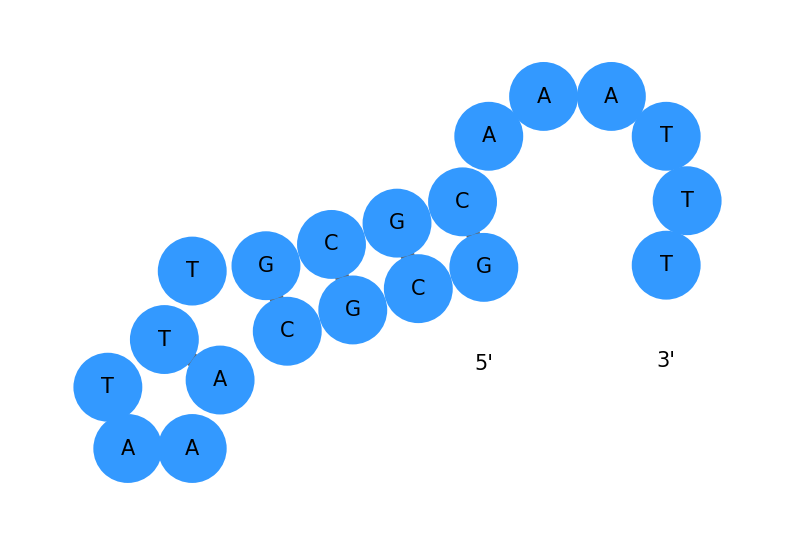

Text(0.5, 1.0, 'Single strand – MFE = -3.70 kcal/mol')

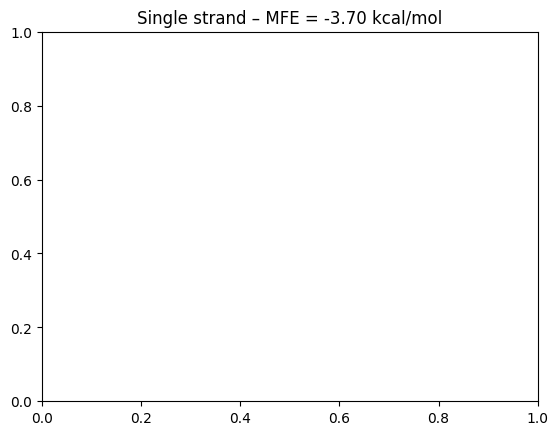

In [4]:
# Draw the secondary structure
print("Drawing structure for:", seq1)
drawseq([seq1], T=T, sodium=sodium)
plt.title(f"Single strand – MFE = {result1[0].energy:.2f} kcal/mol")

Strand 1  : GCGCAAATTTGCGCAAATTT
Strand 2  : AAATTTGCGCAAATTTGCGC
Structure : ((((((((((((((((((((+))))))))))))))))))))
MFE (ΔG)  : -35.176761627197266 kcal/mol


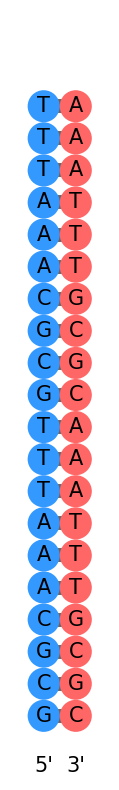

[StructureEnergy(Structure('((((((((((((((((((((+))))))))))))))))))))'), energy=-35.176761627197266, stack_energy=-35.176761627197266)]

In [5]:
# --- 1b: two complementary sequences together ---
# When two strands are complementary they base-pair → lower (more negative) ΔG

seq1a = "GCGCAAATTTGCGCAAATTT"
seq1b = "AAATTTGCGCAAATTTGCGC"   # reverse complement of seq1a

result2 = mfe([seq1a, seq1b], model)

print("Strand 1  :", seq1a)
print("Strand 2  :", seq1b)
print("Structure :", result2[0].structure)
print("MFE (ΔG)  :", result2[0].energy, "kcal/mol")

drawseq([seq1a, seq1b], T=T, sodium=sodium)

Length 10 nt → MFE = 0.00 kcal/mol
Length 20 nt → MFE = -3.70 kcal/mol
Length 30 nt → MFE = -11.54 kcal/mol
Length 40 nt → MFE = -22.05 kcal/mol


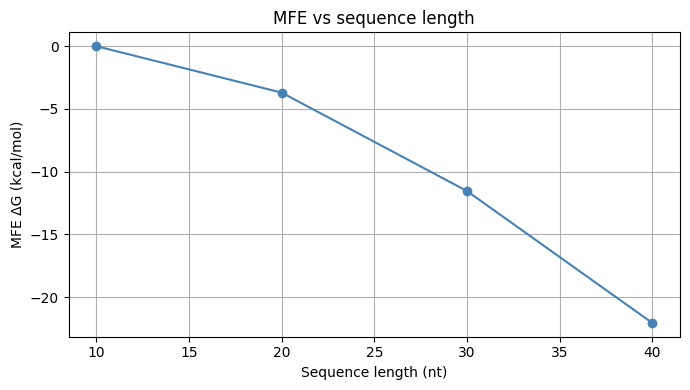

In [6]:
# --- 1c: how does energy depend on sequence length? ---
# Let's try the same motif at lengths 10, 20, 30, 40 nt

base_seq = "GCGCAAATTT"   # 10-nt motif
lengths  = [10, 20, 30, 40]
energies = []

for L in lengths:
    # repeat the motif to reach the desired length
    repeats = L // len(base_seq)
    s = (base_seq * repeats)[:L]
    res = mfe([s], model)
    energies.append(res[0].energy)
    print(f"Length {L:2d} nt → MFE = {res[0].energy:.2f} kcal/mol")

plt.figure(figsize=(7, 4))
plt.plot(lengths, energies, marker='o', color='steelblue')
plt.xlabel("Sequence length (nt)")
plt.ylabel("MFE ΔG (kcal/mol)")
plt.title("MFE vs sequence length")
plt.grid(True)
plt.tight_layout()
plt.show()

### Answer to Q1

- The MFE (ΔG) becomes **more negative** as the sequence gets longer: 0.0, -3.7, -11.5 and -22.1 kcal/mol for 10, 20, 30 and 40 nt of the same repeated motif.
- A longer strand has more bases → more chances to form internal hairpins and base-pair with itself. The 10-nt strand cannot fold at all (ΔG = 0).
- Two complementary strands together give a much lower ΔG than each strand alone (-35.2 against -3.7 kcal/mol) because they form a full duplex.
- I only varied the length here, not the base composition. In general GC-rich sequences are more stable than AT-rich ones, but I did not test that in this notebook.

---
## Question 2 – Tube analysis: free energy of complexes

**Goal:** put two sequences in a "tube" and use `tube_analysis` to compute MFE and partition function (pfunc) for complexes up to size n=2 (or n=3). Understand why energy grows with complex size.

> **What is a tube?**  
> A tube simulates a solution containing multiple DNA strands at defined concentrations.  
> NUPACK will consider all ways the strands can combine (1-strand complexes, 2-strand complexes, etc.).

In [7]:
# --- 2: tube analysis with two sequences ---

# Define two 20-nt sequences
seqA = Strand("GCGCAAATTTGCGCAAATTT", name="A")
seqB = Strand("AAATTTGCGCAAATTTGCGC", name="B")

# Put them in a tube at equal concentration (1 µM each)
conc = 1e-6   # 1 micromolar
t1 = Tube(
    strands={seqA: conc, seqB: conc},
    complexes=SetSpec(max_size=2),   # consider 1-strand and 2-strand complexes
    name="MyTube"
)

model = Model(material="dna", celsius=20, sodium=1)

# Run the analysis
results = tube_analysis(
    tubes=[t1],
    compute=["mfe", "pfunc"],
    model=model
)

print("Tube analysis complete!")

Tube analysis complete!


In [8]:
# Print and visualise the results for each complex

for complex_obj, complex_result in results.complexes.items():
    strands_in_complex = list(complex_obj.strands)
    names = [s.name for s in strands_in_complex]
    mfe_energy = complex_result.mfe[0].energy
    pfunc_value = complex_result.pfunc

    print(f"Complex: {names}")
    print(f"  MFE structure : {complex_result.mfe[0].structure}")
    print(f"  MFE energy    : {mfe_energy:.4f} kcal/mol")
    print(f"  Partition func: {pfunc_value:.4e}")
    print()

Complex: ['A', 'B']
  MFE structure : ((((((((((((((((((((+))))))))))))))))))))
  MFE energy    : -35.1768 kcal/mol
  Partition func: 2.6606e+26

Complex: ['B']
  MFE structure : ......(((((...).))))
  MFE energy    : -3.4883 kcal/mol
  Partition func: 8.4460e+2

Complex: ['B', 'B']
  MFE structure : ......((((((((((((((+......))))))))))))))
  MFE energy    : -28.7046 kcal/mol
  Partition func: 1.4039e+21

Complex: ['A', 'A']
  MFE structure : ((((((((((((((......+))))))))))))))......
  MFE energy    : -29.1304 kcal/mol
  Partition func: 2.8147e+21

Complex: ['A']
  MFE structure : (((((...).))))......
  MFE energy    : -3.7012 kcal/mol
  Partition func: 1.2001e+3



Drawing the A+B complex:


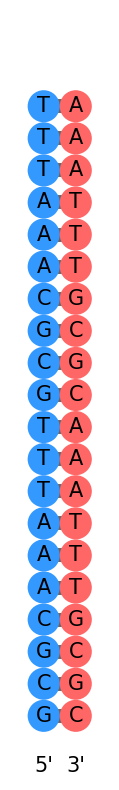

[StructureEnergy(Structure('((((((((((((((((((((+))))))))))))))))))))'), energy=-35.176761627197266, stack_energy=-35.176761627197266)]

In [9]:
# Draw the MFE structure of the A+B duplex
print("Drawing the A+B complex:")
drawseq([str(seqA), str(seqB)], T=20, sodium=1)

In [11]:
# --- Optional: extend to max_size=3 with three sequences ---

seqC = Strand("TTTTAAAACCCCGGGGAAAA", name="C")

t2 = Tube(
    strands={seqA: conc, seqB: conc, seqC: conc},
    complexes=SetSpec(max_size=3),
    name="ThreeTube"
)

results3 = tube_analysis(
    tubes=[t2],
    compute=["mfe", "pfunc"],
    model=model
)

print("=== Three-strand tube: all complexes ===")
for cx, cx_res in results3.complexes.items():
    names = [s.name for s in list(cx.strands)]
    print(f"  {names}  MFE = {cx_res.mfe[0].energy:.3f} kcal/mol  "
          f"pfunc = {cx_res.pfunc:.3e}")

=== Three-strand tube: all complexes ===
  ['A', 'B', 'C']  MFE = -39.215 kcal/mol  pfunc = 4.829e+29
  ['C']  MFE = -0.660 kcal/mol  pfunc = 1.193e+1
  ['C', 'C', 'C']  MFE = -31.089 kcal/mol  pfunc = 4.196e+23
  ['A', 'A', 'C']  MFE = -35.494 kcal/mol  pfunc = 1.429e+27
  ['B', 'B', 'B']  MFE = -41.689 kcal/mol  pfunc = 2.852e+31
  ['A', 'A', 'B']  MFE = -46.660 kcal/mol  pfunc = 1.347e+35
  ['A', 'B', 'B']  MFE = -46.447 kcal/mol  pfunc = 9.399e+34
  ['A']  MFE = -3.701 kcal/mol  pfunc = 1.200e+3
  ['A', 'B']  MFE = -35.177 kcal/mol  pfunc = 2.661e+26
  ['A', 'C', 'C']  MFE = -29.230 kcal/mol  pfunc = 5.124e+22
  ['B']  MFE = -3.488 kcal/mol  pfunc = 8.446e+2
  ['A', 'C', 'B']  MFE = -39.663 kcal/mol  pfunc = 6.064e+30
  ['A', 'A', 'A']  MFE = -42.354 kcal/mol  pfunc = 8.534e+31
  ['A', 'A']  MFE = -29.130 kcal/mol  pfunc = 2.815e+21
  ['B', 'C', 'C']  MFE = -28.326 kcal/mol  pfunc = 3.130e+22
  ['A', 'C']  MFE = -10.065 kcal/mol  pfunc = 3.112e+8
  ['B', 'B']  MFE = -28.705 kcal/mo

### Answer to Q2

- As the complex size grows (from 1-strand → 2-strand → 3-strand), the **MFE energy gets more negative** – the complex becomes more stable because more base-pairs can form.
- The **partition function (pfunc)** tells us the total "statistical weight" of all possible structures. A higher pfunc = more ways to fold = more entropy.
- The MFE energy is **higher (less negative) than the free energy** derived from pfunc because the MFE only counts the single best structure, while pfunc counts all structures. The ensemble average is more negative due to contributions from many structures.

---
## Question 3 – Tube analysis at different concentrations

**Goal:** analyze how the concentration of the strands affects binding.

[total] = 1e-09 M  →  fraction as duplex = 1.000
[total] = 1e-08 M  →  fraction as duplex = 1.000
[total] = 1e-07 M  →  fraction as duplex = 1.000
[total] = 1e-06 M  →  fraction as duplex = 1.000
[total] = 1e-05 M  →  fraction as duplex = 1.000


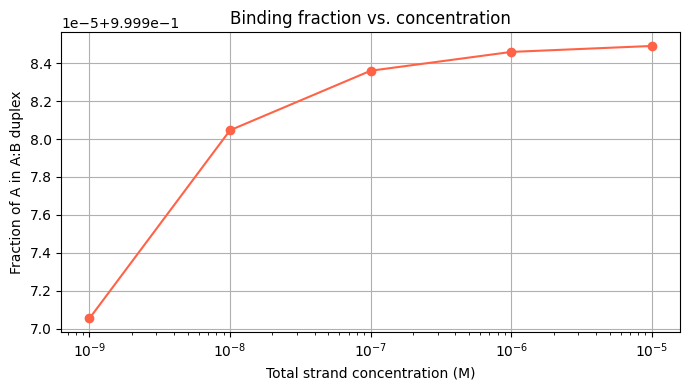

In [12]:
# --- 3: vary the strand concentration ---

# Same two strands as before
strandA = Strand("GCGCAAATTTGCGCAAATTT", name="A")
strandB = Strand("AAATTTGCGCAAATTTGCGC", name="B")

model = Model(material="dna", celsius=20, sodium=1)

# Try several concentrations spanning many orders of magnitude
concentrations = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]   # 1 nM to 10 µM

# We will store the concentration of the A+B duplex at each total concentration
duplex_fractions = []

for c in concentrations:
    tube = Tube(
        strands={strandA: c, strandB: c},
        complexes=SetSpec(max_size=2),
        name="tube"
    )
    res = tube_analysis(tubes=[tube], compute=["mfe", "pfunc"], model=model)

    # Find the A+B complex and get its equilibrium concentration
    for cx, cx_res in res.complexes.items():
        names = sorted([s.name for s in list(cx.strands)])
        if names == ["A", "B"]:
            duplex_conc = res.tubes[tube].complex_concentrations[cx]
            duplex_fractions.append(duplex_conc / c)  # fraction bound
            print(f"[total] = {c:.0e} M  →  fraction as duplex = {duplex_conc/c:.3f}")
            break

plt.figure(figsize=(7, 4))
plt.semilogx(concentrations, duplex_fractions, marker='o', color='tomato')
plt.xlabel("Total strand concentration (M)")
plt.ylabel("Fraction of A in A:B duplex")
plt.title("Binding fraction vs. concentration")
plt.grid(True)
plt.tight_layout()
plt.show()

### Answer to Q3

- I expected a simple **bimolecular equilibrium**, A + B ⇌ AB: at low concentrations the strands rarely meet and stay unbound, and at high concentrations the equilibrium shifts towards the duplex.
- In my output this is **not visible**: the fraction of A in the duplex is 1.000 at every concentration I tried, from 1 nM to 10 µM.
- The reason is that these two 20-nt strands are perfectly complementary and the duplex is extremely stable (ΔG ≈ -35 kcal/mol at 20 °C), so the concentration where half of the strands would be unbound is far below 1 nM.
- To see the concentration dependence I would need a weaker pair, for example shorter strands or strands with mismatches, or a higher temperature. I did not do this here.

---
## Question 4 – ΔG distribution: test sequence vs. random sequences

**Goal:** take a test sequence of length N. Generate many random sequences of the same length. Compute the MFE of each random sequence paired with the test sequence. Plot the distribution of ΔG values.

In [13]:
# --- 4: ΔG distribution ---

import random

# Fix a random seed so results are reproducible
random.seed(42)
np.random.seed(42)

# Test sequence (our "target")
N = 20
test_seq = "GCGCAAATTTGCGCAAATTT"   # 20 nt

model = Model(material="dna", celsius=20, sodium=1)

# Generate 200 random sequences of length N
num_random = 200
bases = ["A", "T", "G", "C"]
random_seqs = ["".join(random.choices(bases, k=N)) for _ in range(num_random)]

# Compute MFE for each random sequence paired with the test sequence
delta_G_list = []

for i, rseq in enumerate(random_seqs):
    res = mfe([test_seq, rseq], model)
    delta_G_list.append(res[0].energy)
    if (i + 1) % 50 == 0:
        print(f"  Done {i+1}/{num_random}")

print("\nAll done!")
print(f"Mean ΔG = {np.mean(delta_G_list):.2f} kcal/mol")
print(f"Min  ΔG = {np.min(delta_G_list):.2f} kcal/mol  (most stable random match)")
print(f"Max  ΔG = {np.max(delta_G_list):.2f} kcal/mol  (least stable)")

  Done 50/200
  Done 100/200
  Done 150/200
  Done 200/200

All done!
Mean ΔG = -10.75 kcal/mol
Min  ΔG = -16.66 kcal/mol  (most stable random match)
Max  ΔG = -7.46 kcal/mol  (least stable)


Perfect complement: AAATTTGCGCAAATTTGCGC
Perfect complement ΔG = -35.18 kcal/mol


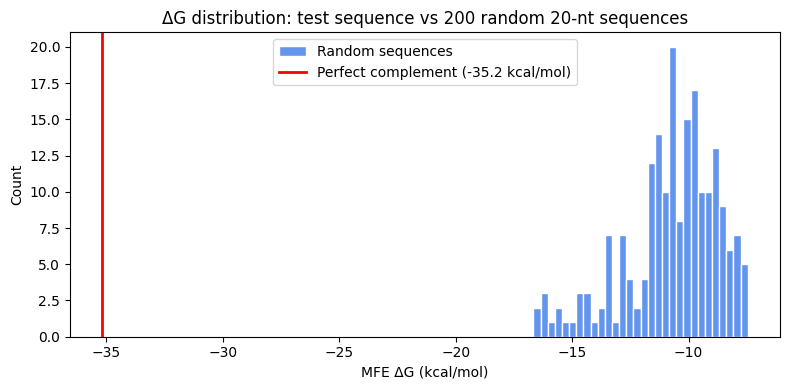

In [14]:
# Compute the MFE of the perfect complement (best possible match)
perfect_complement = test_seq.translate(str.maketrans("ATGC", "TACG"))[::-1]
res_perfect = mfe([test_seq, perfect_complement], model)
perfect_dG = res_perfect[0].energy

print("Perfect complement:", perfect_complement)
print(f"Perfect complement ΔG = {perfect_dG:.2f} kcal/mol")

# Plot the histogram
plt.figure(figsize=(8, 4))
plt.hist(delta_G_list, bins=30, color='cornflowerblue', edgecolor='white', label='Random sequences')
plt.axvline(perfect_dG, color='red', linewidth=2, label=f'Perfect complement ({perfect_dG:.1f} kcal/mol)')
plt.xlabel("MFE ΔG (kcal/mol)")
plt.ylabel("Count")
plt.title(f"ΔG distribution: test sequence vs {num_random} random {N}-nt sequences")
plt.legend()
plt.tight_layout()
plt.show()

### Answer to Q4

- The ΔG distribution for random sequences looks roughly **Gaussian (bell-shaped)**, centered around a negative value.
- Even random sequences have *some* partial complementarity by chance → all ΔG values are negative.
- The **perfect complement** is a clear outlier far to the left (much more negative ΔG) – it is significantly more stable than any random match.
- The tail of the distribution shows that a few random sequences happen to have quite good (but not perfect) complementarity with the test sequence.

---
## Question 5 – Probability of finding a good interaction in a genome

**Goal:** if you have a genome of length L = 10⁹ bp, what is the probability of finding a sequence that interacts well with a given probe of length N = 20 nt?

In [15]:
# --- 5: probability calculation ---

# Parameters
N = 20          # probe length in nt
L = 1e9         # genome length in bp

# Number of distinct subsequences of length N in the genome
# Each position in the genome gives one N-nt window → approx L windows
num_windows = L - N + 1   # basically L for large L
print(f"Number of possible {N}-nt windows in the genome: {num_windows:.2e}")

# --- Approach 1: purely random sequence model ---
# Total number of distinct sequences of length N (assuming equal base frequencies)
total_possible = 4**N
print(f"\nTotal distinct {N}-nt sequences: 4^{N} = {total_possible:.2e}")

# Probability that ONE random window is the exact complement
p_exact_one = 1 / total_possible
print(f"P(one window = perfect complement): {p_exact_one:.2e}")

# Probability of finding the perfect complement at LEAST once in the whole genome
# P(at least one) = 1 - P(none)
p_none = (1 - p_exact_one) ** num_windows
p_at_least_one = 1 - p_none
print(f"\nP(perfect complement found in genome): {p_at_least_one:.4f}")

Number of possible 20-nt windows in the genome: 1.00e+09

Total distinct 20-nt sequences: 4^20 = 1.10e+12
P(one window = perfect complement): 9.09e-13

P(perfect complement found in genome): 0.0009


In [16]:
# --- Approach 2: use the ΔG distribution from Q4 ---
# Define a threshold ΔG below which we call an interaction "good"
# (e.g. more negative than the mean minus 2 standard deviations)

mean_dG = np.mean(delta_G_list)
std_dG  = np.std(delta_G_list)
threshold = mean_dG - 2 * std_dG   # "good" = unusually stable

# Fraction of random sequences that pass the threshold
num_good = np.sum(np.array(delta_G_list) < threshold)
p_good_single = num_good / len(delta_G_list)

print(f"Mean ΔG        : {mean_dG:.2f} kcal/mol")
print(f"Std  ΔG        : {std_dG:.2f} kcal/mol")
print(f"Threshold      : {threshold:.2f} kcal/mol  (mean - 2σ)")
print(f"Fraction 'good': {p_good_single:.3f}  ({num_good}/{len(delta_G_list)} random seqs)")

# Expected number of "good" hits in the genome
expected_good_hits = p_good_single * num_windows
print(f"\nExpected number of good hits in the genome: {expected_good_hits:.2e}")

Mean ΔG        : -10.75 kcal/mol
Std  ΔG        : 2.01 kcal/mol
Threshold      : -14.77 kcal/mol  (mean - 2σ)
Fraction 'good': 0.050  (10/200 random seqs)

Expected number of good hits in the genome: 5.00e+07


N = 10  →  expected perfect matches = 9.54e+02
N = 12  →  expected perfect matches = 5.96e+01
N = 14  →  expected perfect matches = 3.73e+00
N = 16  →  expected perfect matches = 2.33e-01
N = 18  →  expected perfect matches = 1.46e-02
N = 20  →  expected perfect matches = 9.09e-04
N = 22  →  expected perfect matches = 5.68e-05
N = 24  →  expected perfect matches = 3.55e-06
N = 26  →  expected perfect matches = 2.22e-07
N = 28  →  expected perfect matches = 1.39e-08
N = 30  →  expected perfect matches = 8.67e-10
N = 32  →  expected perfect matches = 5.42e-11
N = 34  →  expected perfect matches = 3.39e-12


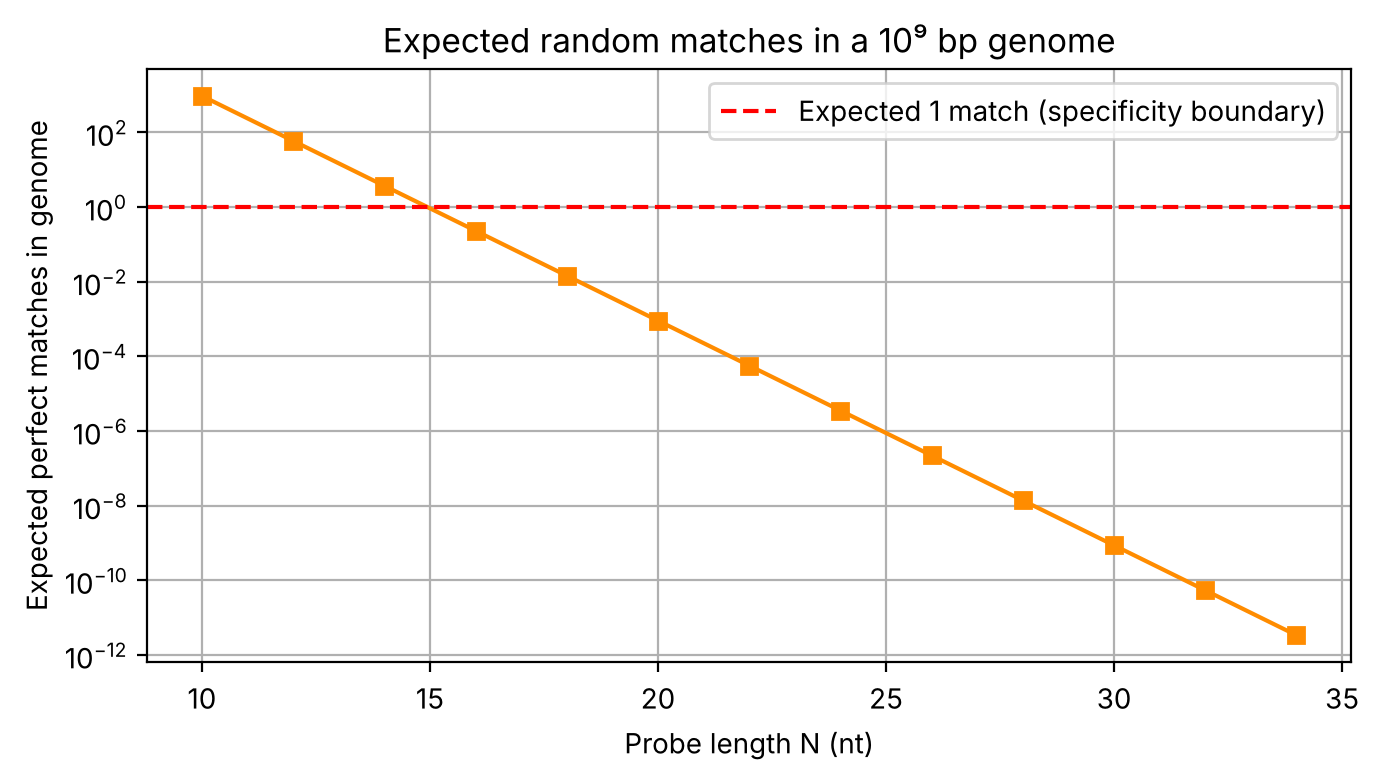

In [17]:
# --- How does probe length affect specificity? ---
# Longer probes → fewer random matches → more specific

probe_lengths = np.arange(10, 35, 2)
expected_matches = []

for n in probe_lengths:
    # Probability of a perfect random match at any single window
    p_one = 1 / (4.0**n)   # 4.0 so that large n does not overflow
    # Expected number of perfect matches in the genome
    exp = p_one * L
    expected_matches.append(exp)
    print(f"N = {n:2d}  →  expected perfect matches = {exp:.2e}")

plt.figure(figsize=(7, 4))
plt.semilogy(probe_lengths, expected_matches, marker='s', color='darkorange')
plt.axhline(1, color='red', linestyle='--', label='Expected 1 match (specificity boundary)')
plt.xlabel("Probe length N (nt)")
plt.ylabel("Expected perfect matches in genome")
plt.title("Expected random matches in a 10⁹ bp genome")
plt.legend()
plt.grid(True, which='both')
plt.tight_layout()
plt.show()

### Answer to Q5

**How many random matches do we expect?**

| Probe length N | Total 4ᴺ sequences | Expected perfect hits in 10⁹ genome |
|:-:|:-:|:-:|
| 10 nt | ~10⁶ | ~1000 |
| 15 nt | ~10⁹ | ~1 |
| 20 nt | ~10¹² | ~0.001 |

**Key insight:** For a genome of 10⁹ bp, we cross the "specificity threshold" (expected matches < 1) at around **N ≈ 15 nt**.

- A probe of **N = 20 nt** is essentially **unique** in a 10⁹ bp genome: the probability of finding the exact complement by chance is about 10⁻³.
- This is exactly why **PCR primers and CRISPR guides are ~20 nt long** – it balances specificity (long enough to be unique) with practicality (short enough to synthesize cheaply and bind efficiently).
- From the ΔG distribution, none of the 200 random sequences comes close to the perfect complement (the best one has -16.7 kcal/mol, against -35.2). With the looser definition I used above (ΔG below the mean minus 2σ, i.e. below -14.8 kcal/mol), 5% of random sequences count as "good", which would give about 5 × 10⁷ windows in the genome. So a probe has very many weak partial matches in a genome, but they bind much more weakly than the real target, and this is what makes it possible to choose conditions where only the target stays bound.